# Power analysis GWAS synthetic data with additive effect

In [204]:
import pandas as pd
import numpy as np
import os
import math
import seaborn as sns
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from scipy import stats

In [205]:
chrom = 22

In [206]:
humans = pd.read_csv('./data/phenotype/all.panel',delim_whitespace=True)
humans

,sample,sample.1,pop,super_pop,gender
0,HG00096,HG00096,GBR,EUR,male
1,HG00097,HG00097,GBR,EUR,female
2,HG00099,HG00099,GBR,EUR,female
3,HG00100,HG00100,GBR,EUR,female
4,HG00101,HG00101,GBR,EUR,male
...,...,...,...,...,...
2499,NA21137,NA21137,GIH,SAS,female
2500,NA21141,NA21141,GIH,SAS,female
2501,NA21142,NA21142,GIH,SAS,female
2502,NA21143,NA21143,GIH,SAS,female


In [207]:
os.listdir(f"./data/genotype/chrom_{chrom}")

['11_5_961_11_maf_0.32_0.38.pkl',
 '5_6_800_5_maf_0.067_0.091.pkl',
 '0_3_802_0_maf_0.01_0.016.pkl',
 '7_2_1200_7_maf_0.12_0.16.pkl',
 '1_8_800_1_maf_0.016_0.023.pkl',
 '4_7_800_4_maf_0.049_0.067.pkl',
 '5_8_800_5_maf_0.067_0.091.pkl',
 '0_0_815_0_maf_0.01_0.016.pkl',
 '10_6_800_10_maf_0.26_0.32.pkl',
 '1_6_1200_1_maf_0.016_0.023.pkl',
 '12_7_800_12_maf_0.38_0.45.pkl',
 '2_7_800_2_maf_0.023_0.035.pkl',
 '12_0_1200_12_maf_0.38_0.45.pkl',
 '6_9_972_6_maf_0.091_0.12.pkl',
 '6_4_1200_6_maf_0.091_0.12.pkl',
 '7_7_1135_7_maf_0.12_0.16.pkl',
 '7_0_1200_7_maf_0.12_0.16.pkl',
 '9_8_1076_9_maf_0.21_0.26.pkl',
 '0_7_800_0_maf_0.01_0.016.pkl',
 '7_9_800_7_maf_0.12_0.16.pkl',
 '7_1_800_7_maf_0.12_0.16.pkl',
 '8_3_800_8_maf_0.16_0.21.pkl',
 '5_2_1200_5_maf_0.067_0.091.pkl',
 '3_5_800_3_maf_0.035_0.049.pkl',
 '3_1_1200_3_maf_0.035_0.049.pkl',
 '5_0_1200_5_maf_0.067_0.091.pkl',
 '4_4_1009_4_maf_0.049_0.067.pkl',
 '11_3_1016_11_maf_0.32_0.38.pkl',
 '7_3_1189_7_maf_0.12_0.16.pkl',
 '2_9_800_2_maf_0.023_

In [208]:
#wanted_maf = '0.01_0.01'
#wanted_maf = '0.024_0.025'
#wanted_maf = '0.048_0.05'
#wanted_maf = '0.49_0.49'
wanted_maf = '0.32_0.38'
#wanted_maf = '0.25_0.25'

In [209]:
snps = [f for f in os.listdir(f"./data/genotype/chrom_{chrom}") if f.split("_maf_")[1].split('.pkl')[0] == wanted_maf]
for snp in snps:
    maf = snp.split("_maf_")[1].split('.pkl')[0]
    path_snp = f"./data/genotype/chrom_{chrom}/{snp}"
    print(path_snp)

./data/genotype/chrom_22/11_5_961_11_maf_0.32_0.38.pkl
./data/genotype/chrom_22/11_3_1016_11_maf_0.32_0.38.pkl
./data/genotype/chrom_22/11_4_1131_11_maf_0.32_0.38.pkl
./data/genotype/chrom_22/11_1_883_11_maf_0.32_0.38.pkl
./data/genotype/chrom_22/11_6_800_11_maf_0.32_0.38.pkl
./data/genotype/chrom_22/11_9_1200_11_maf_0.32_0.38.pkl
./data/genotype/chrom_22/11_8_1200_11_maf_0.32_0.38.pkl
./data/genotype/chrom_22/11_7_800_11_maf_0.32_0.38.pkl
./data/genotype/chrom_22/11_2_1200_11_maf_0.32_0.38.pkl
./data/genotype/chrom_22/11_0_809_11_maf_0.32_0.38.pkl


In [210]:
geno = pd.read_pickle(path_snp)
i = 0

In [211]:
geno[geno.columns[i]].value_counts()
num_maj = geno[geno.columns[i]].value_counts()[1]
num_het = geno[geno.columns[i]].value_counts()[0]
try:
    num_min = geno[geno.columns[i]].value_counts()[-1]
except Exception as e:
    num_min = 0
total_humans = num_maj + num_het + num_min

In [212]:
maf = (num_min*2 + num_het)/(total_humans*2)
maf

0.319888178913738

In [213]:
mean_min_H0 = 0
mean_het_H0 = 0
mean_maj_H0 = 0

In [214]:
true_mean = 160
true_effect = 5
true_sd = 40

In [215]:
mean_min = true_mean - true_effect
mean_het = true_mean
mean_maj = true_mean + true_effect
sigma_min = true_sd
sigma_het = true_sd
sigma_maj = true_sd
pheno = []
for var in list(geno[geno.columns[i]]):
    if var == 1:
        pheno.append(np.random.normal(mean_maj, sigma_maj, 1)[0])
    elif var == 0:
        pheno.append(np.random.normal(mean_het, sigma_het, 1)[0])
    else:
        pheno.append(np.random.normal(mean_min, sigma_min, 1)[0])
df_pheno = pd.DataFrame(data = {"geno": list(geno[geno.columns[i]]), "pheno": pheno})

In [216]:
df_pheno

,geno,pheno
0,-1,124.522192
1,0,137.006153
2,1,245.635079
3,1,138.041338
4,0,131.111122
...,...,...
2499,1,153.139165
2500,0,138.767488
2501,1,191.118551
2502,-1,164.648641


<AxesSubplot:xlabel='geno', ylabel='pheno'>

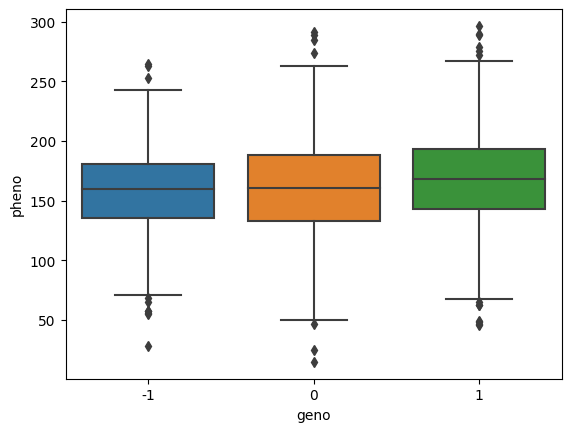

In [217]:
sns.boxplot(data=df_pheno, x="geno", y="pheno")

In [218]:
def standy(pandasdf):
    print(stats.tstd(pandasdf))
    return (pandasdf - pandasdf.mean())/stats.tstd(pandasdf)

In [219]:
X = df_pheno[['geno']]
y = df_pheno[['pheno']]

In [220]:
#y = standy(df_pheno[['pheno']])
#X = standy(df_pheno[['geno']])
#df_pheno['std_geno'] = X
#df_pheno['std_pheno'] = y

In [221]:
df_pheno

,geno,pheno
0,-1,124.522192
1,0,137.006153
2,1,245.635079
3,1,138.041338
4,0,131.111122
...,...,...
2499,1,153.139165
2500,0,138.767488
2501,1,191.118551
2502,-1,164.648641


In [222]:
reg = LinearRegression().fit(X, y)

In [223]:
reg.score(X, y)

0.0090977293023069

In [224]:
estimated_effect = reg.coef_[0][0]
estimated_effect

5.478390024409024

In [225]:
estimated_intercept = reg.intercept_[0]
estimated_intercept

161.65709280088922

In [226]:
def find_lin_reg(X):
    y = reg.coef_[0][0]*X + reg.intercept_[0]
    return y

In [227]:
find_lin_reg(1)

167.13548282529825

In [228]:
estimated_effect

5.478390024409024

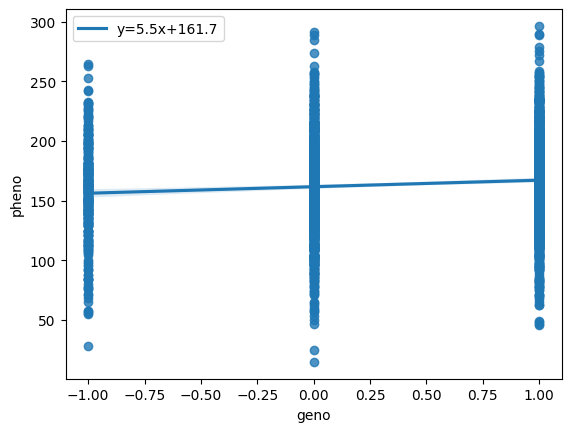

In [229]:
# use line_kws to set line label for legend
ax = sns.regplot(x="geno", y="pheno", data=df_pheno, 
 line_kws={'label':"y={0:.1f}x+{1:.1f}".format(estimated_effect,estimated_intercept)})

# plot legend
ax.legend()

plt.show()

In [230]:
N = len(X)
p = len(X.columns) + 1

X_with_intercept = np.empty(shape=(N, p), dtype=float)
X_with_intercept[:, 0] = 1
X_with_intercept[:, 1:p] = X.values

params = np.append(reg.intercept_,reg.coef_)
predictions = reg.predict(X)
new_y = (y-predictions)**2
newX = pd.DataFrame({"Constant":np.ones(len(X))}).join(pd.DataFrame(list(X['geno'])))
MSE = (sum(list(new_y['pheno'])))/(len(newX)-len(newX.columns))

var_b = MSE*(np.linalg.inv(np.dot(newX.T,newX)).diagonal())
sd_b = np.sqrt(var_b)
ts_b = params/ sd_b

print(f"var = {var_b}")
print(f"sd = {sd_b}")
print(f"t_square = {ts_b}")
p_values =[2*(1-stats.t.cdf(np.abs(i),(len(newX)-len(newX.columns)))) for i in ts_b]

residuals = y - predictions
residual_sum_of_squares = residuals.T @ residuals
sigma_squared_hat = residual_sum_of_squares['pheno'].pheno / (N - p)
var_beta_hat = np.linalg.inv(X_with_intercept.T @ X_with_intercept) * sigma_squared_hat

SE = []
for p_ in range(p):
    standard_error = var_beta_hat[p_, p_] ** 0.5
    SE.append(standard_error)
    print(f"SE(beta_hat[{p_}]): {standard_error}")

sd_b = np.round(sd_b,3)
ts_b = np.round(ts_b,3)
params = np.round(params,4)

var = [0.79831357 1.30652103]
sd = [0.89348395 1.14303151]
t_square = [180.92892775   4.79286003]
SE(beta_hat[0]): 0.8934839486885275
SE(beta_hat[1]): 1.1430315072585966


In [231]:
p_values

[0.0, 1.74047534473587e-06]

# Power

In [232]:
total_humans

2504

In [233]:
maf

0.319888178913738

In [234]:
number_of_tests = 5000

In [235]:
alt = estimated_effect
alt

5.478390024409024

In [236]:
X

,geno
0,-1
1,0
2,1
3,1
4,0
...,...
2499,1
2500,0
2501,1
2502,-1


## create random phenotype with no link to the genotype

In [237]:
mean_min = true_mean
mean_het = true_mean
mean_maj = true_mean
sigma_min = true_sd
sigma_het = true_sd
sigma_maj = true_sd
pheno = []
for var in list(geno[geno.columns[i]]):
    if var == 1:
        pheno.append(np.random.normal(mean_maj, sigma_maj, 1)[0])
    elif var == 0:
        pheno.append(np.random.normal(mean_het, sigma_het, 1)[0])
    else:
        pheno.append(np.random.normal(mean_min, sigma_min, 1)[0])
df_pheno['pheno_null'] = pheno

In [238]:
df_pheno

,geno,pheno,pheno_null
0,-1,124.522192,130.739129
1,0,137.006153,123.779992
2,1,245.635079,169.262941
3,1,138.041338,147.816987
4,0,131.111122,122.209429
...,...,...,...
2499,1,153.139165,169.131807
2500,0,138.767488,112.077118
2501,1,191.118551,181.627413
2502,-1,164.648641,152.321839


In [239]:
# SE under nul hypothesis
X = df_pheno[['geno']]
y = df_pheno[['pheno_null']]
reg = LinearRegression().fit(X, y)

In [240]:
N = len(X)
p = len(X.columns) + 1

X_with_intercept = np.empty(shape=(N, p), dtype=float)
X_with_intercept[:, 0] = 1
X_with_intercept[:, 1:p] = X.values

params = np.append(reg.intercept_,reg.coef_)
predictions = reg.predict(X)
new_y = (y-predictions)**2
newX = pd.DataFrame({"Constant":np.ones(len(X))}).join(pd.DataFrame(list(X['geno'])))
MSE = (sum(list(new_y['pheno_null'])))/(len(newX)-len(newX.columns))

var_b = MSE*(np.linalg.inv(np.dot(newX.T,newX)).diagonal())
sd_b = np.sqrt(var_b)
ts_b = params/ sd_b
print(f"var = {var_b}")
print(f"sd = {sd_b}")
print(f"t_square = {ts_b}")

p_values =[2*(1-stats.t.cdf(np.abs(i),(len(newX)-len(newX.columns)))) for i in ts_b]

residuals = y - predictions
residual_sum_of_squares = residuals.T @ residuals
sigma_squared_hat = residual_sum_of_squares['pheno_null'][0] / (N - p)
var_beta_hat = np.linalg.inv(X_with_intercept.T @ X_with_intercept) * sigma_squared_hat
SE = []
for p_ in range(p):
    standard_error = var_beta_hat[p_, p_] ** 0.5
    SE.append(standard_error)
    print(f"SE(beta_hat[{p_}]): {standard_error}")

sd_b = np.round(sd_b,3)
ts_b = np.round(ts_b,3)
params = np.round(params,4)

var = [0.81237967 1.32954164]
sd = [0.90132107 1.15305752]
t_square = [175.63060496   0.93421046]
SE(beta_hat[0]): 0.9013210720645114
SE(beta_hat[1]): 1.1530575171921509


In [241]:
SE[1]

1.1530575171921509

In [242]:
distribution_nul = np.random.normal(0, SE[1], 5000)
distribution_alt = np.random.normal(estimated_effect, SE[1], 5000)
labels = ['nul hypothesis']*len(distribution_nul) + ['alternate hypothesis'] * len(distribution_alt)
dis = pd.DataFrame(data={"Z": list(distribution_nul)+list(distribution_alt), 'labels': labels})

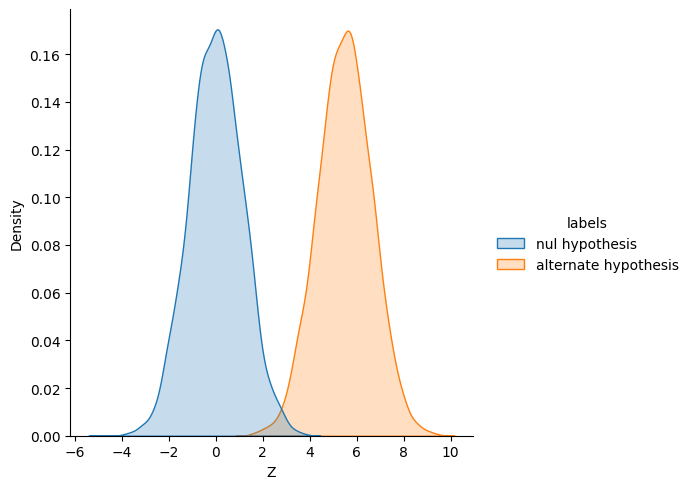

In [243]:
sns.displot(dis, x="Z", hue='labels',kind="kde",fill=True)

In [244]:
distribution_nul = np.random.normal(0, SE[1], 5000)**2
distribution_alt = np.random.normal(estimated_effect, SE[1], 5000)**2
labels = ['nul hypothesis']*len(distribution_nul) + ['alternate hypothesis'] * len(distribution_alt)
dis = pd.DataFrame(data={"Z2": list(distribution_nul)+list(distribution_alt), 'labels': labels})

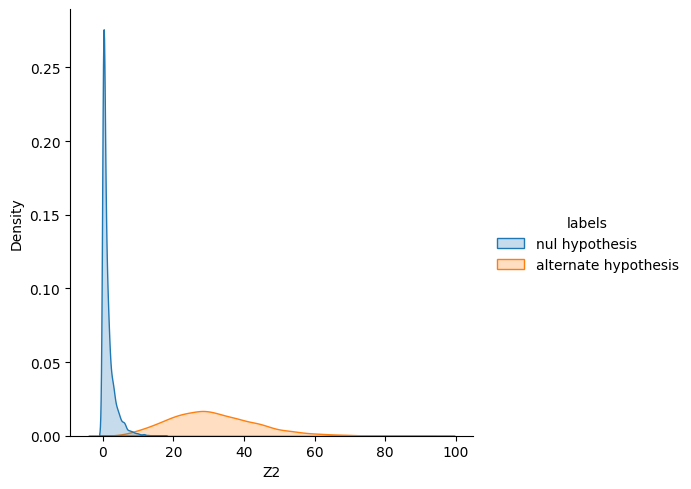

In [245]:
sns.displot(dis, x="Z2", hue='labels',kind="kde",fill=True)

In [246]:
stats.chi2.ppf(0.99, df=1)

6.6348966010212145